In [1]:
print("Supriya K 24BAD118")

import os
import zipfile
import shutil
import random
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Upload Kaggle Dataset
from google.colab import files
uploaded = files.upload()

# 2. Extract Dataset
zip_path = "/content/archive.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
# 3. Dataset Paths
source_train = "/content/dataset/PandasBears/Train"
source_test = "/content/dataset/PandasBears/Test"

classes = ["Bears", "Pandas"]
# 4. Create Train, Validation and Test Folders
base_dir = "/content/pandas_bears"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")
test_dir = os.path.join(base_dir, "test")
for folder in [train_dir, val_dir, test_dir]:
    for cls in classes:
        os.makedirs(os.path.join(folder, cls), exist_ok=True)
# 5. Split Training Data: 80% Train, 20% Validation
random.seed(42)
for cls in classes:
    path = os.path.join(source_train, cls)
    images = [
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    random.shuffle(images)
    split = int(0.8 * len(images))
    train_images = images[:split]
    val_images = images[split:]
    for img in train_images:
        shutil.copy(
            os.path.join(path, img),
            os.path.join(train_dir, cls, img)
        )
    for img in val_images:
        shutil.copy(
            os.path.join(path, img),
            os.path.join(val_dir, cls, img)
        )
# 6. Copy Test Images
for cls in classes:
    path = os.path.join(source_test, cls)
    for img in os.listdir(path):
        if img.lower().endswith((".jpg", ".jpeg", ".png")):
            shutil.copy(
                os.path.join(path, img),
                os.path.join(test_dir, cls, img)
            )
# 7. Load and Preprocess Images
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
datagen = ImageDataGenerator(rescale=1./255)
train_data = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)
validation_data = datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)
test_data = datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)
print("Dataset preparation completed!")
print("Training:", train_data.samples)
print("Validation:", validation_data.samples)
print("Testing:", test_data.samples)

Supriya K 24BAD118


Saving archive.zip to archive.zip
Dataset extracted successfully!
Found 400 images belonging to 2 classes.
Found 100 images belonging to 2 classes.
Found 100 images belonging to 2 classes.
Dataset preparation completed!
Training: 400
Validation: 100
Testing: 100


In [ ]:
print("Supriya k 24BAD118")
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (
    Dense,
    GlobalAveragePooling2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
# 2. LOAD PRE-TRAINED RESNET-50
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(
        224,
        224,
        3
    )
)
print("ResNet-50 loaded successfully!")
# 3. FREEZE FEATURE EXTRACTION LAYERS
base_model.trainable = False
print(
    "Feature extraction layers are frozen."
)
# 4. ADD CLASSIFICATION LAYERS
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(
    128,
    activation="relu"
)(x)
output = Dense(
    1,
    activation="sigmoid"
)(x)

# 5. CREATE FINAL MODEL

model = Model(

    inputs=base_model.input,

    outputs=output
)
# 6. DISPLAY MODEL
model.summary()
# 7. COMPILE MODEL
model.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy"
    ]
)
print("\nModel compiled successfully!")


Supriya k 24BAD118
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ResNet-50 loaded successfully!
Feature extraction layers are frozen.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


Model compiled successfully!


Supriya K 24BAD118
Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 113s 4s/step - accuracy: 0.6725 - loss: 0.6617 - val_accuracy: 0.9100 - val_loss: 0.6189
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 109s 4s/step - accuracy: 0.7875 - loss: 0.6161 - val_accuracy: 0.9300 - val_loss: 0.5676
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 98s 4s/step - accuracy: 0.8100 - loss: 0.5822 - val_accuracy: 0.7500 - val_loss: 0.5394
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 91s 4s/step - accuracy: 0.8850 - loss: 0.5404 - val_accuracy: 0.9500 - val_loss: 0.4820
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 94s 4s/step - accuracy: 0.8725 - loss: 0.5146 - val_accuracy: 0.9600 - val_loss: 0.4436
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 80s 3s/step - accuracy: 0.8650 - loss: 0.4893 - val_accuracy: 0.9900 - val_loss: 0.4118
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 82s 3s/step - accuracy: 0.8725 - loss: 0.4692 - val_accuracy: 0.8900 - val_loss: 0.4105
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.8875 - loss: 0.4472 - val_accurac

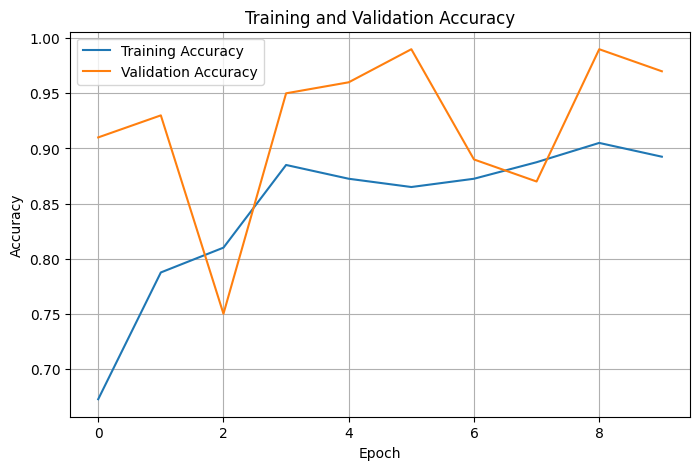

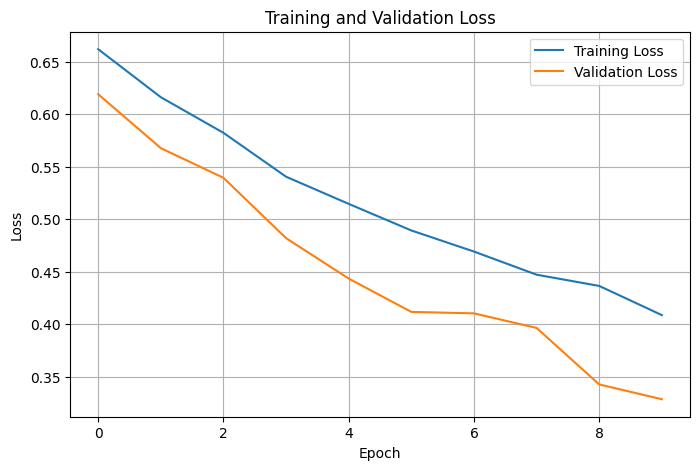


PART C COMPLETED


In [ ]:

# 1. DEFINE NUMBER OF EPOCHS
print("Supriya K 24BAD118")
EPOCHS = 10
# 2. TRAIN THE MODEL
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS
)
# 3. TRAINING ACCURACY
training_accuracy = history.history[
    "accuracy"
]
print(
    "Final Training Accuracy:",
    training_accuracy[-1]
)
# 4. VALIDATION ACCURACY
validation_accuracy = history.history[
    "val_accuracy"
]
print(
    "Final Validation Accuracy:",
    validation_accuracy[-1]
)
# 5. TRAINING LOSS
training_loss = history.history[
    "loss"
]
print(
    "Final Training Loss:",
    training_loss[-1]
)
# 6. VALIDATION LOSS
validation_loss = history.history[
    "val_loss"
]
print(
    "Final Validation Loss:",
    validation_loss[-1]
)
# 7. TEST THE MODEL
test_loss, test_accuracy = model.evaluate(
    test_generator
)
print(
    "\nTest Loss:",
    test_loss
)
print(
    "Test Accuracy:",
    test_accuracy
)
# 8. PRINT FINAL RESULTS
print("FINAL MODEL RESULTS")
print(
    "Training Accuracy  :",
    round(
        training_accuracy[-1] * 100,
        2
    ),
    "%"
)
print(
    "Validation Accuracy:",
    round(
        validation_accuracy[-1] * 100,
        2
    ),
    "%"
)
print(
    "Training Loss      :",
    round(
        training_loss[-1],
        4
    )
)
print(
    "Validation Loss    :",
    round(
        validation_loss[-1],
        4
    )
)
print(
    "Test Accuracy      :",
    round(
        test_accuracy * 100,
        2
    ),
    "%"
)
# 9. ACCURACY VS EPOCH
plt.figure(
    figsize=(8, 5)
)
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel(
    "Epoch"
)
plt.ylabel(
    "Accuracy"
)
plt.title(
    "Training and Validation Accuracy"
)
plt.legend()
plt.grid()
plt.show()
# 10. LOSS VS EPOCH
plt.figure(
    figsize=(8, 5)
)
plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel(
    "Epoch"
)
plt.ylabel(
    "Loss"
)
plt.title(
    "Training and Validation Loss"
)
plt.legend()
plt.grid()
plt.show()


Supriya K 24BAD118


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Hugging Face Vision Transformer loaded!
Sample Image: 275.jpeg


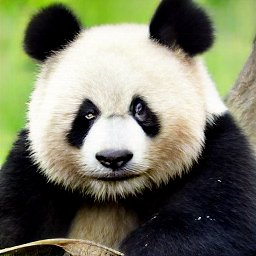

     HUGGING FACE PREDICTION
giant panda, panda, panda bear, coon bear, Ailuropoda melanoleuca -> 0.995
lesser panda, red panda, panda, bear cat, cat bear, Ailurus fulgens -> 0.0022
ice bear, polar bear, Ursus Maritimus, Thalarctos maritimus -> 0.0003
sloth bear, Melursus ursinus, Ursus ursinus -> 0.0003
brown bear, bruin, Ursus arctos -> 0.0002
RESNET-50 PREDICTION
Predicted Class: Pandas
Confidence: 0.8235
 MODEL COMPARISON
Actual Class: Pandas
ResNet-50 Prediction: Pandas
ResNet-50 Confidence: 0.8235

Hugging Face Top Predictions:
giant panda, panda, panda bear, coon bear, Ailuropoda melanoleuca -> 0.995
lesser panda, red panda, panda, bear cat, cat bear, Ailurus fulgens -> 0.0022
ice bear, polar bear, Ursus Maritimus, Thalarctos maritimus -> 0.0003
sloth bear, Melursus ursinus, Ursus ursinus -> 0.0003
brown bear, bruin, Ursus arctos -> 0.0002


In [ ]:
print("Supriya K 24BAD118")
# 1. INSTALL HUGGING FACE TRANSFORMERS

!pip install -q TRANSFORMERS

# 2. IMPORT REQUIRED LIBRARIES

from transformers import pipeline
from PIL import Image

# 3. LOAD HUGGING FACE PRE-TRAINED MODEL

hf_classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224"
)
print(
    "Hugging Face Vision Transformer loaded!"
)

# 4. SELECT SAMPLE IMAGE

sample_class = "Pandas"
sample_folder = os.path.join(
    test_dir,
    sample_class
)
sample_files = [
    file for file in os.listdir(
        sample_folder
    )
    if file.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]
sample_image_name = sample_files[0]
sample_image_path = os.path.join(
    sample_folder,
    sample_image_name
)

# 5. LOAD IMAGE

image = Image.open(
    sample_image_path
).convert("RGB")
print(
    "Sample Image:",
    sample_image_name
)
display(image)

# 6. HUGGING FACE PREDICTION

hf_result = hf_classifier(
    image
)
print("     HUGGING FACE PREDICTION")
for result in hf_result[:5]:
    print(
        result["label"],
        "->",
        round(
            result["score"],
            4
        )
    )

# 7. RESNET-50 PREDICTION

image_resized = image.resize(
    IMG_SIZE
)
image_array = np.array(
    image_resized
)
image_array = image_array / 255.0
image_array = np.expand_dims(
    image_array,
    axis=0
)
prediction = model.predict(
    image_array,
    verbose=0
)[0][0]

# 8. CONVERT PREDICTION TO CLASS

if prediction >= 0.5:
    resnet_class = "Pandas"
    resnet_confidence = prediction
else:
    resnet_class = "Bears"
    resnet_confidence = 1 - prediction

# 9. DISPLAY RESNET-50 RESULT

print("RESNET-50 PREDICTION")
print(
    "Predicted Class:",
    resnet_class
)
print(
    "Confidence:",
    round(
        float(resnet_confidence),
        4
    )
)

# 10. COMPARE MODELS

print(" MODEL COMPARISON")
print(
    "Actual Class:",
    sample_class
)
print(
    "ResNet-50 Prediction:",
    resnet_class
)
print(
    "ResNet-50 Confidence:",
    round(
        float(resnet_confidence),
        4
    )
)
print(
    "\nHugging Face Top Predictions:"
)
for result in hf_result[:5]:
    print(
        result["label"],
        "->",
        round(
            result["score"],
            4
        )
    )